# 121 · A reusable evaluation harness: fixed seeds, per-task rates, intervals, paired perturbations

In [1]:
import numpy as np, matplotlib.pyplot as plt, inspect
from vlacourse import TableTop, ExpertPolicy, evaluate, wilson
from vlacourse.eval_suite import run_suite, SUITE

class NoisyExpert(ExpertPolicy):
    """A deliberately imperfect 'policy under test': the expert with action noise."""
    def __init__(self, env, sigma, seed=0):
        super().__init__(env); self.sigma, self.rng = sigma, np.random.default_rng(seed)
    def act(self, obs):
        a = super().act(obs); a[:3] += self.rng.normal(0, self.sigma, 3); return a

def table(results, title):
    names = list(results); s = np.array([results[n]["success"] for n in names]); ci = np.array([results[n]["ci"] for n in names])
    plt.figure(figsize=(9, 0.5 * len(names) + 1.5))
    plt.barh(names, s, xerr=[s - ci[:, 0], ci[:, 1] - s], capsize=3); plt.xlim(0, 1.05); plt.gca().invert_yaxis(); plt.title(title); plt.xlabel("success (95% Wilson CI)"); plt.show()

In [2]:
print(inspect.signature(evaluate))
env = TableTop(cameras=("front",), image_size=(96, 96), seed=0)
r = evaluate(env, ExpertPolicy(env), n_episodes=30, seed=10_000)
print(f"scripted expert: {r['success']:.2f} CI {np.round(r['ci'], 2)} per task {r['per_task']}")
print("first episodes:", r["episodes"][:3])

(env, policy, n_episodes=50, seed=10000, max_steps=None, record=0, camera='front', on_step=None, on_reset=None)


scripted expert: 1.00 CI [0.89 1.  ] per task {'place': 1.0, 'pick': 1.0, 'stack': 1.0}
first episodes: [{'task': 'place', 'instruction': 'put the red cube in the yellow tray', 'success': True, 'steps': 44}, {'task': 'place', 'instruction': 'put the blue cube in the yellow tray', 'success': True, 'steps': 44}, {'task': 'pick', 'instruction': 'pick up the green cube', 'success': True, 'steps': 26}]


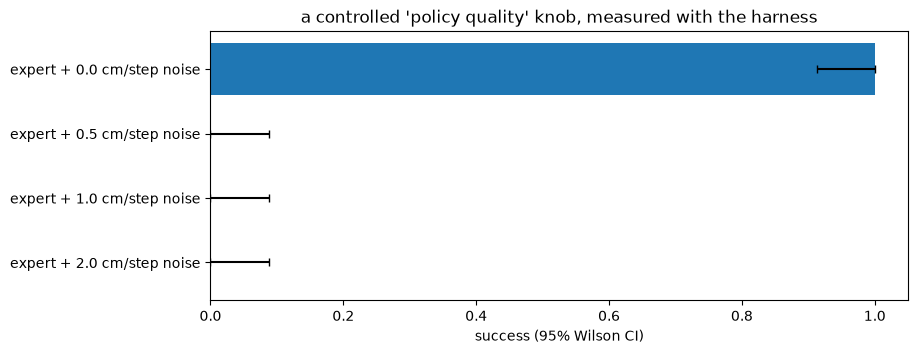

In [3]:
rows = {}
for sigma in [0.0, 0.005, 0.01, 0.02]:
    rows[f"expert + {sigma * 100:.1f} cm/step noise"] = evaluate(env, NoisyExpert(env, sigma), n_episodes=40, seed=10_000)
table(rows, "a controlled 'policy quality' knob, measured with the harness")

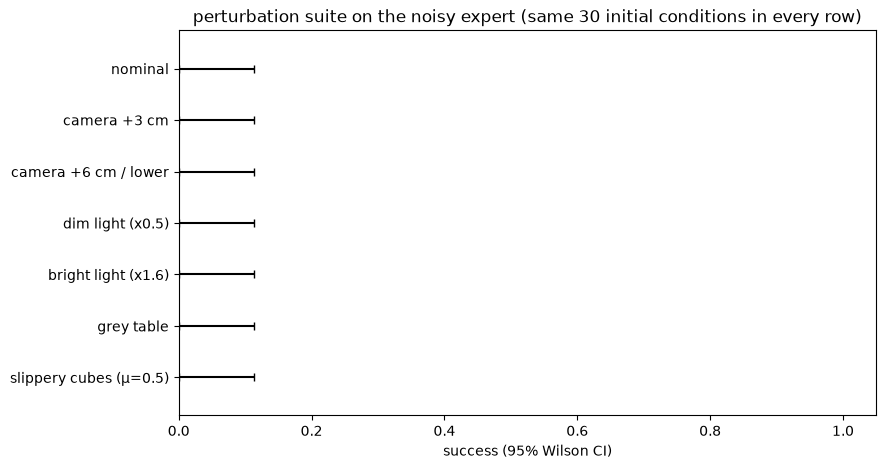

camera +3 cm             paired vs nominal: lost  0, gained  0 episodes
camera +6 cm / lower     paired vs nominal: lost  0, gained  0 episodes
dim light (x0.5)         paired vs nominal: lost  0, gained  0 episodes
bright light (x1.6)      paired vs nominal: lost  0, gained  0 episodes
grey table               paired vs nominal: lost  0, gained  0 episodes
slippery cubes (μ=0.5)   paired vs nominal: lost  0, gained  0 episodes


In [4]:
suite = run_suite(env, NoisyExpert(env, 0.01), n_episodes=30)
table(suite, "perturbation suite on the noisy expert (same 30 initial conditions in every row)")
nominal = suite["nominal"]["episodes"]
for name, res in suite.items():
    if name == "nominal":
        continue
    lost = sum(a["success"] and not b["success"] for a, b in zip(nominal, res["episodes"]))
    gained = sum(b["success"] and not a["success"] for a, b in zip(nominal, res["episodes"]))
    print(f"{name:24s} paired vs nominal: lost {lost:2d}, gained {gained:2d} episodes")